In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import skew, kurtosis, chi2_contingency, probplot
file_path = "/Users/tomamely/Desktop/Ironhack 2025/amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(file_path)
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [13]:
ct = pd.crosstab(df['category'], df['isBestSeller'])
ct.head()


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [14]:
ct['best_seller_proportion'] = ct[True] / ct.sum(axis=1)
ct

isBestSeller,False,True,best_seller_proportion
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [15]:
ct_sorted = ct.sort_values('best_seller_proportion', ascending=False)
ct_sorted


isBestSeller,False,True,best_seller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [17]:
chi2, p, dof, expected = chi2_contingency(ct.iloc[:, :-1])
print(f"Chi-squared: {chi2}, p-value: {p}, degrees of freedom: {dof}")


Chi-squared: 36540.20270061387, p-value: 0.0, degrees of freedom: 295


In [23]:
def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k-1, r-1))

cramers_v_value = cramers_v(ct.iloc[:, :-1])
print(f"Cramér's V: {cramers_v_value:.3f}")

Cramér's V: 0.122


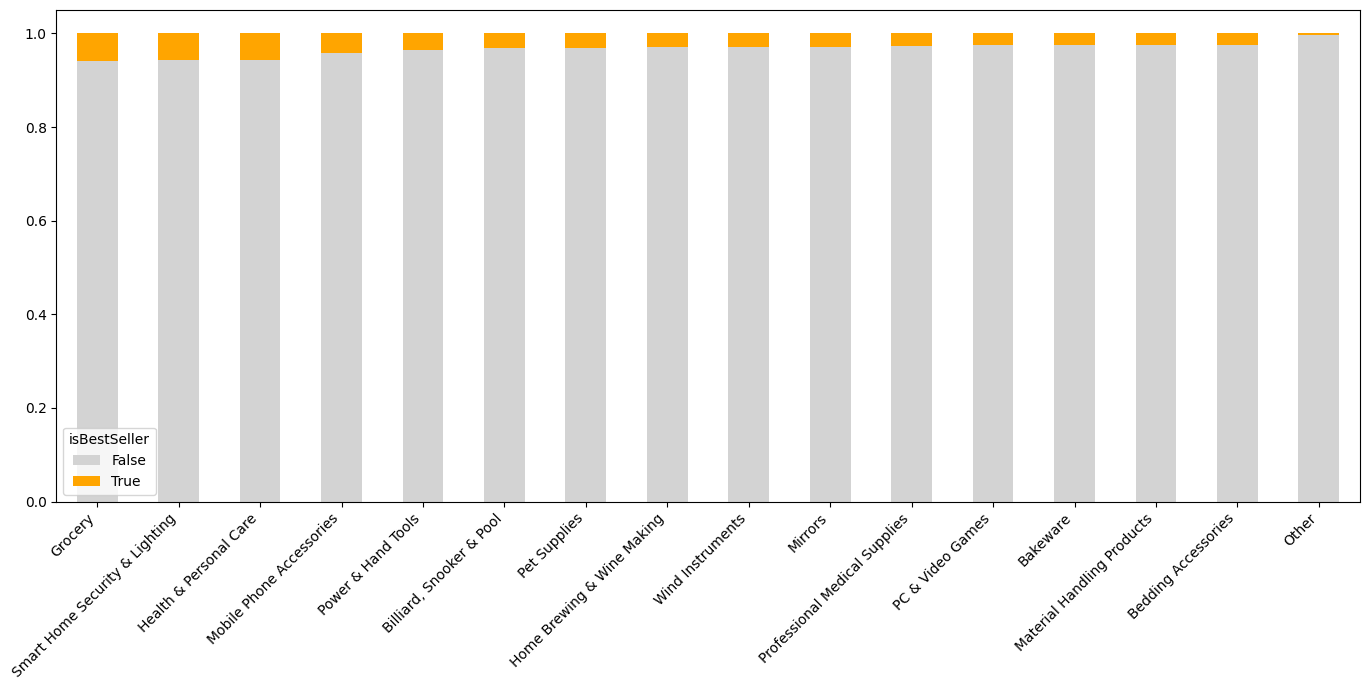

In [26]:
top_n = 15
sorted_ct = ct.sort_values('best_seller_proportion', ascending=False)
top_ct = sorted_ct.head(top_n)
other_ct = sorted_ct.iloc[top_n:].sum()

other_row = pd.DataFrame(other_ct).T
other_row.index = ['Other']

combined_ct = pd.concat([top_ct, other_row])

ct_normalized_combined = combined_ct.iloc[:, :-1].div(combined_ct.iloc[:, :-1].sum(axis=1), axis=0)

ax = ct_normalized_combined.plot(kind='bar', stacked=True, figsize=(14, 7), color=['lightgray', 'orange'])
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()



In [29]:
import pandas as pd

# Assuming your dataframe is called df_products and has columns: 'category', 'price', 'rating'

# Calculate Q1, Q3 and IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for non-outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


/var/folders/nd/m5ygx_wn1pg8b_rwctvdksd80000gn/T/ipykernel_41185/4021183086.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_no_outliers['category_grouped'] = df_no_outliers['category'].apply(
/var/folders/nd/m5ygx_wn1pg8b_rwctvdksd80000gn/T/ipykernel_41185/4021183086.py:14: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=df_no_outliers, x='category_grouped', y='price', inner='quartile', scale='width')


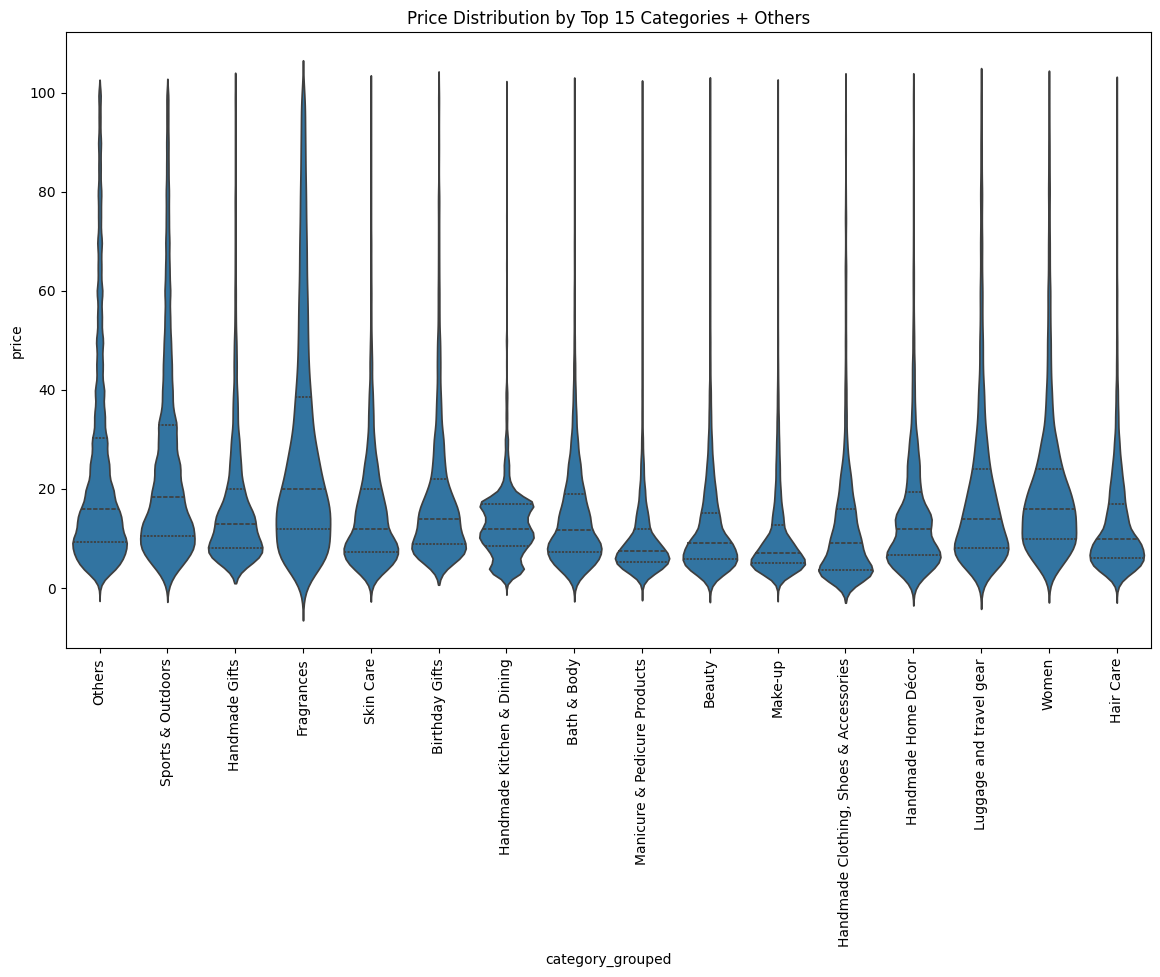

In [31]:
# Считаем количество товаров в каждой категории
category_counts = df_no_outliers['category'].value_counts()

# Выбираем топ-15 категорий
top_15_categories = category_counts.head(15).index

# Создаем новую колонку с группировкой категорий: топ-15 остаются, остальные в 'Others'
df_no_outliers['category_grouped'] = df_no_outliers['category'].apply(
    lambda x: x if x in top_15_categories else 'Others'
)

# Строим violin plot по новой колонке с группировкой
plt.figure(figsize=(14, 8))
sns.violinplot(data=df_no_outliers, x='category_grouped', y='price', inner='quartile', scale='width')
plt.xticks(rotation=90)
plt.title('Price Distribution by Top 15 Categories + Others')
plt.show()


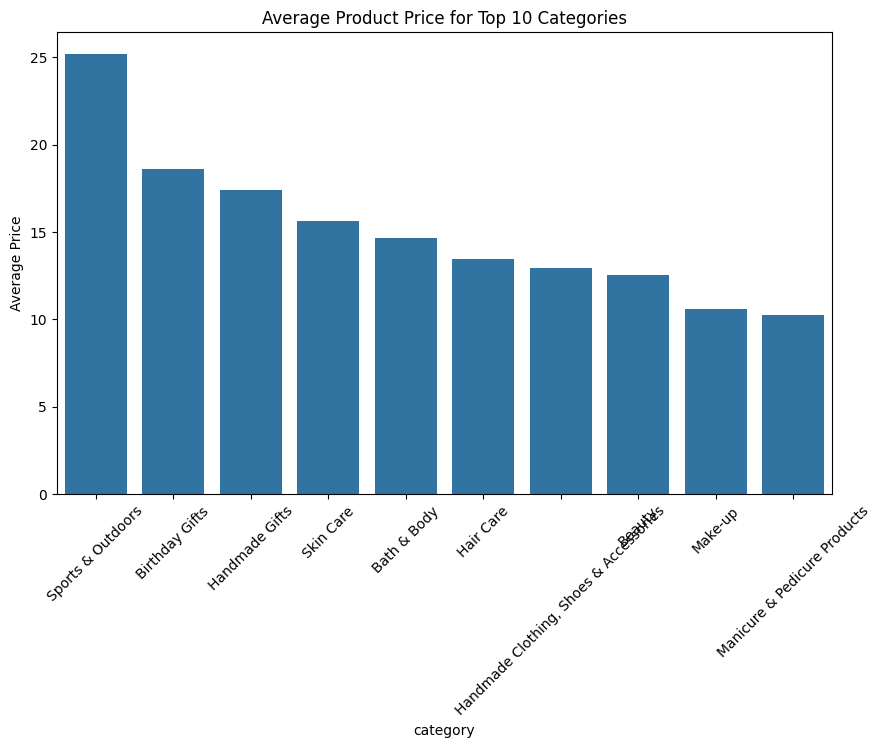

Category with highest average price (all): Motherboards


In [32]:
top_10_cats = df_no_outliers['category'].value_counts().head(10).index
avg_price_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_cats)] \
                    .groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values)
plt.xticks(rotation=45)
plt.title('Average Product Price for Top 10 Categories')
plt.ylabel('Average Price')
plt.show()

# Category with highest average price (no filter)
avg_price_all = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
print("Category with highest average price (all):", avg_price_all.index[0])


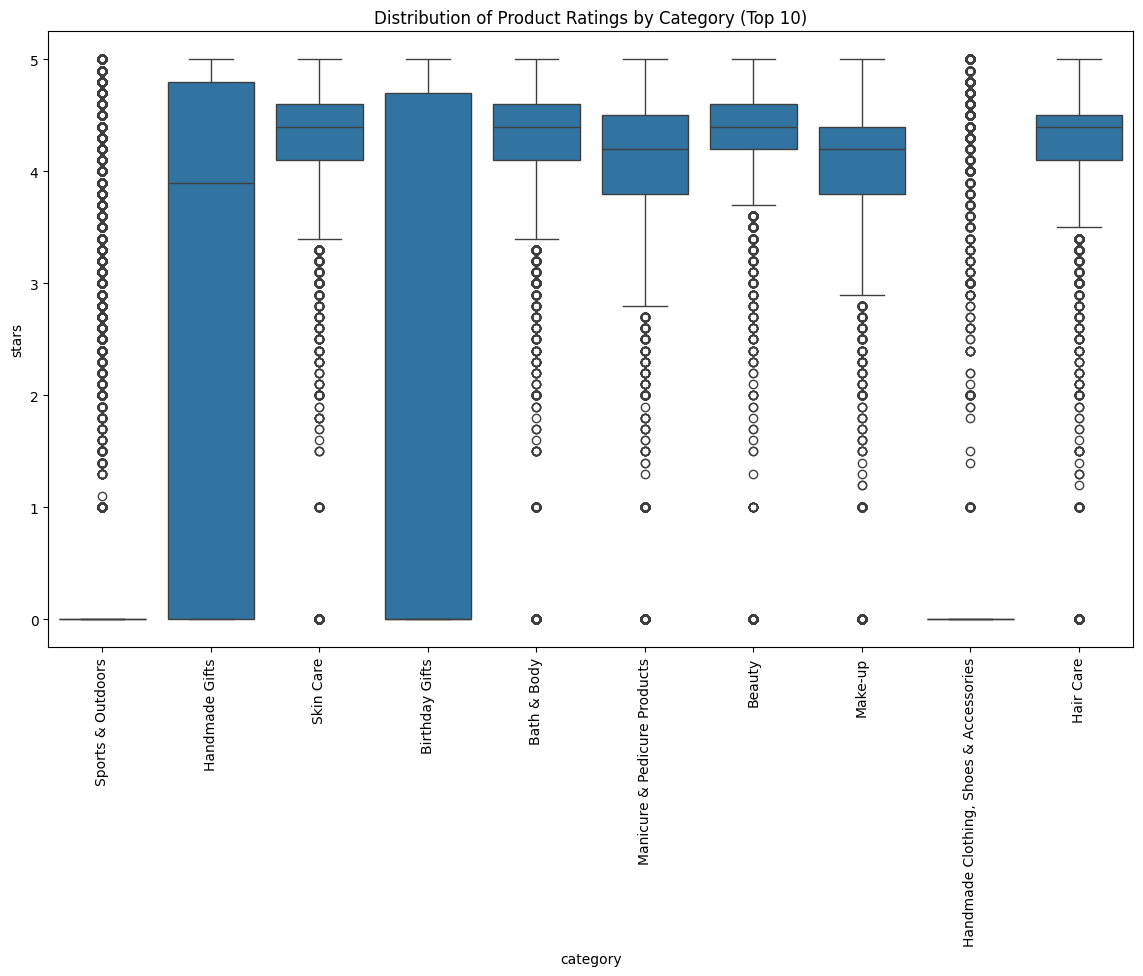

Category with highest median stars (all): Computer Memory


In [34]:
top_10_cats_rating = df_no_outliers['category'].value_counts().head(10).index
df_rating_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_cats_rating)]

plt.figure(figsize=(14, 8))
sns.boxplot(data=df_rating_top10, x='category', y='stars')
plt.xticks(rotation=90)
plt.title('Distribution of Product Ratings by Category (Top 10)')
plt.show()

# Highest median rating category (no filter)
median_rating = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
print("Category with highest median stars (all):", median_rating.index[0])


In [35]:
corr = df['price'].corr(df['stars'])
print(f"Correlation between price and stars: {corr:.3f}")

Correlation between price and stars: -0.125


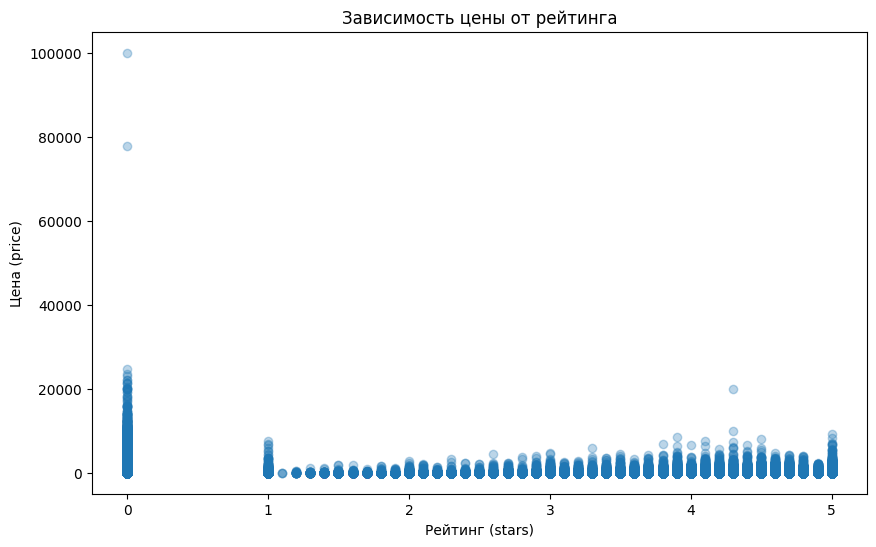

In [37]:


plt.figure(figsize=(10, 6))
plt.scatter(df['stars'], df['price'], alpha=0.3)
plt.xlabel('Рейтинг (stars)')
plt.ylabel('Цена (price)')
plt.title('Зависимость цены от рейтинга')
plt.show()


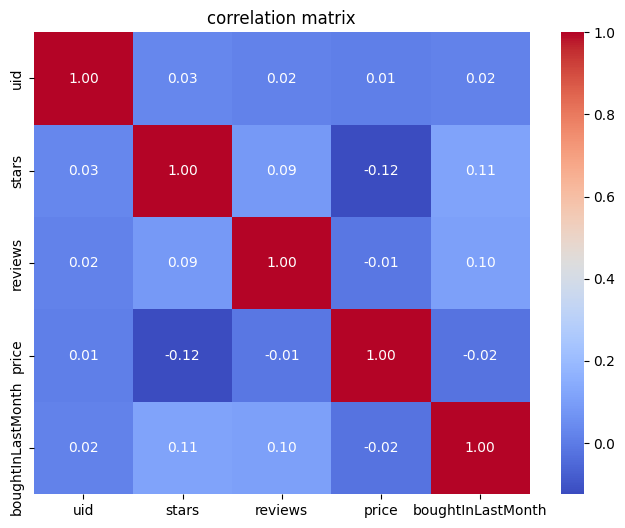

In [39]:
import seaborn as sns

numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('correlation matrix')
plt.show()


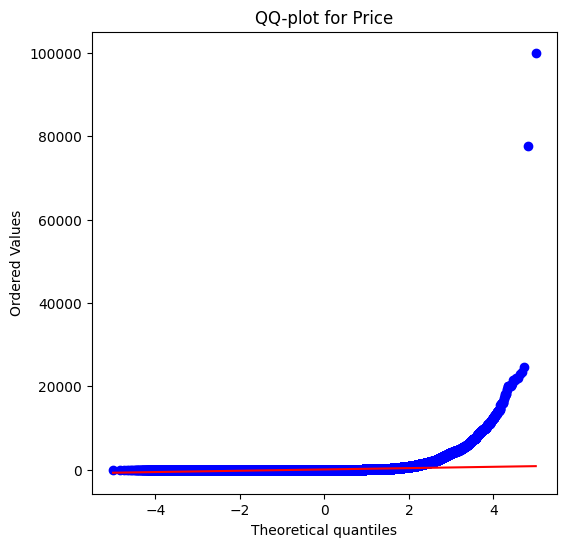

In [46]:
import matplotlib.pyplot as plt
from scipy.stats import probplot

plt.figure(figsize=(6, 6))
probplot(df['price'], dist="norm", plot=plt)
plt.title('QQ-plot for Price')
plt.show()